# AATest

[All Quick Tutorials](README.md)

Use `AATest` for two tasks.

- **Assign users to groups.** Retrieve the selected assignment from `best_split`. Enable `stratification=True` if you need to maintain group proportions within segments.
- **Run an A/A/n diagnostic.** Repeat splits with `dry_test=True` under identical conditions in control and treatment. Use the results to estimate the false-positive rate and check the p-value distribution.

## Contents

- [Why repeat the split?](#aa-theory)
- [Prepare historical data](#aa-data)
- [Assign users to groups](#aa-split)
  - [Run an unstratified split](#aa-simple-split)
  - [Split within strata](#aa-strata)
  - [Read the score across candidate splits](#aa-read-score)
  - [Inspect the selected assignments](#aa-read-assignments)
  - [Check control shares by stratum](#aa-stratum-shares)
- [Create a control and several test groups](#aa-groups)
- [Control how many splits to evaluate](#aa-speed)
  - [Use subsampling and early stopping](#aa-sampling-stopping)
  - [Compare the number of evaluated splits](#aa-compare-trials)
- [Check the Type I error rate with A/A](#aa-diagnostic)
  - [Set the number of diagnostic runs](#aa-configure-dry-test)
  - [Read the uniformity test result](#aa-read-diagnostic)
  - [Display the p-value distribution](#aa-p-value-plot)
- [Reduce floating-point precision](#aa-float32)
- [Define a custom search grid](#aa-grid)
- [Compare variance assumptions](#aa-equal-variance)
- [Check categorical balance](#aa-categorical)
- [Find an example by argument](#aa-arguments)

<a id="aa-theory"></a>

## Why repeat the split?

For an exactly calibrated continuous test under the null hypothesis, $P(p\le\alpha)=\alpha$. Across $B$ candidate splits, estimate the false-positive rate as

$$
\widehat{\mathrm{FPR}}=\frac{1}{B}\sum_{b=1}^{B}\mathbf{1}\{p_b<\alpha\}.
$$

The same users may appear in multiple splits, so treat this rate as a diagnostic for this dataset. Within each split, the t-test compares means and the KS test compares distributions. [NIST two-sample KS test](https://itl.nist.gov/div898/software/dataplot/refman1/auxillar/ks2samp.htm)

<a id="aa-data"></a>

## Prepare historical data

Use `Target_lag_1` as the historical metric and `X_lag_1` to define strata.

In [1]:
import pandas as pd

from hypex import AATest
from hypex.dataset import Dataset, StratificationRole, TargetRole
from hypex.splitters import AASplitter
from hypex.utils.tutorial_data_creation import gen_control_variates_df

frame = gen_control_variates_df(
    data_size=1200, dependent_division=False, random_state=42
)
frame[["X_lag_1", "Target_lag_1"]].head(3)

,X_lag_1,Target_lag_1
0,1.899464,389.946418
1,0.472709,247.270884
2,9.207838,1120.783778


The first rows show both historical columns. The candidate split uses these inputs without the original treatment assignments.

<a id="aa-split"></a>

## Assign users to groups

<a id="aa-simple-split"></a>

### Run an unstratified split

Run `AATest` and read the `split` column in `best_split`. `dry_test=False` is the default. Set `random_states=[42]` for one reproducible split. Keep the defaults `control_size=0.5` and `stratification=False` for a 50% control target across the full sample.

In [2]:
split_data = Dataset(
    roles={"Target_lag_1": TargetRole()},
    data=frame[["Target_lag_1"]],
)
plain_split = AATest(random_states=[42]).execute(split_data)
plain_split.best_split.select("split").value_counts()

,split,count
0,control,602
1,test_1,598


This run assigned 602 users to `control` and 598 to `test_1`. Realized proportions can differ slightly from their targets. In `plain_split.best_split`, the `split` column gives the assignment for each original row index.

<a id="aa-strata"></a>

### Split within strata

If the target control share should hold within each segment, such as each region, enable `stratification=True` and assign `StratificationRole` to the segment column. HypEx allocates users within each stratum and returns assignments in `best_split`.

Create two segments from the historical feature `X_lag_1`. `control_size` sets the control share and `random_states` sets the seeds for either kind of split. Here, target 60% control and evaluate five candidate splits. In a stratum of size $n_s$, the target control size is about $0.6n_s$. A nonempty `random_states` list determines the number of candidates, so you can omit `n_iterations`.

In [3]:
frame["segment"] = (frame["X_lag_1"] >= 2.5).map({False: "low", True: "high"})

aa_data = Dataset(
    roles={"Target_lag_1": TargetRole(), "segment": StratificationRole()},
    data=frame[["Target_lag_1", "segment"]],
)
aa = AATest(
    stratification=True,
    control_size=0.6,
    random_states=[10, 11, 12, 13, 14],
).execute(aa_data)
aa.best_split_statistics

,feature,group,control mean,test mean,difference,difference %,TTest pass,TTest p-value,KSTest pass,KSTest p-value
0,Target_lag_1,test_1,436.777258,440.462495,3.685237,0.843734,OK,0.806999,OK,0.538006


The selected split has a difference in means of about 3.69. Both checks for `Target_lag_1` pass at a significance level of 0.05.

<a id="aa-read-score"></a>

### Read the score across candidate splits

Open `aa_score` to see results across the series of splits.

In [4]:
aa.aa_score

,score,pass
Target_lag_1 TTest test_1,0.95,True
Target_lag_1 KSTest test_1,0.95,True


`score` summarizes the series, and `pass` gives the overall status. Inspect individual runs in `aa.experiments`.

<a id="aa-read-assignments"></a>

### Inspect the selected assignments

Inspect the user assignments in the selected split.

In [5]:
aa.best_split.iloc[:5]

,Target_lag_1,segment,split
0,389.946418,low,test_1
1,247.270884,low,control
2,1120.783778,high,test_1
3,909.032404,high,test_1
4,164.738790,low,control


`split` contains `control` or `test_1` for each row, and `segment` identifies its stratum.

<a id="aa-stratum-shares"></a>

### Check control shares by stratum

Check the realized control share separately in each stratum. Compute assignment proportions within each row of the table.

Select the two columns with HypEx, then build a cross-tabulation with pandas.

In [6]:
assignments = aa.best_split.select(["segment", "split"]).data
pd.crosstab(assignments["segment"], assignments["split"], normalize="index").round(3)

split,control,test_1
segment,,
high,0.607,0.393
low,0.602,0.398


The control share is 60.7% in `high` and 60.2% in `low`. Both are close to the 60% target because allocation ran separately within each segment.

<a id="aa-groups"></a>

## Create a control and several test groups

For three or more groups, pass `groups_sizes` in order, starting with control. Use 50%, 25%, and 25% here. With `groups_sizes=None`, `control_size` sets the control share for a two-group split.

Without an explicit `random_states` list, HypEx runs the seeds in `range(n_iterations)`. The default split evaluates 10 candidates. Here, set `n_iterations` to 5.

The first entry in `groups_sizes` already sets the control share and subsequent entries set the test shares. Leave `control_size` at its default for this split.

In [7]:
three_groups = AATest(n_iterations=5, groups_sizes=[0.5, 0.25, 0.25]).execute(
    aa_data
)
three_groups.best_split.select("split").value_counts(normalize=True)

,split,proportion
0,control,0.489167
1,test_2,0.273333
2,test_1,0.237500


The split contains three groups. The realized shares are close to their targets, with small differences due to random assignment.

<a id="aa-speed"></a>

## Control how many splits to evaluate

<a id="aa-sampling-stopping"></a>

### Use subsampling and early stopping

`sample_size=0.5` evaluates candidate splits on half the rows to save time. With `None`, HypEx starts with the full dataset. The sampled search may be followed by a search on all rows. `early_stopping=True` ends the search once a split passes the checks for every feature. Keep early stopping off when estimating the false-positive rate.

Keep `sample_size` and `n_iterations` the same across both runs. Change only `early_stopping` to see how many candidates each run evaluates.

The settings are independent. Use `sample_size` to evaluate a subset or `early_stopping` to evaluate fewer splits. The first call spells out the default `early_stopping=False` for comparison.

In [8]:
sampled = AATest(
    n_iterations=20,
    sample_size=0.5,
    early_stopping=False,
).execute(aa_data)
fast = AATest(
    n_iterations=20,
    sample_size=0.5,
    early_stopping=True,
).execute(aa_data)
{
    "trials without early stopping": len(sampled.experiments),
    "trials with early stopping": len(fast.experiments),
    "rows in best split": len(fast.best_split),
}

{'trials without early stopping': 20,
 'trials with early stopping': 1,
 'rows in best split': 1200}

<a id="aa-compare-trials"></a>

### Compare the number of evaluated splits

With `sample_size=0.5` in both runs, the first evaluates 20 candidate splits and the second stops after one. The final split contains 1,200 rows. `sample_size` controls the candidate evaluation subset, and `early_stopping` controls how many candidates are evaluated.

<a id="aa-diagnostic"></a>

## Check the Type I error rate with A/A

Check how well the t-test is calibrated in the absence of treatment. Repeatedly split the same users into two random groups using one historical metric. For a well-calibrated test, the proportion of splits with `p < 0.05` should be close to the nominal rate of 5%.

<a id="aa-configure-dry-test"></a>

### Set the number of diagnostic runs

Enable `dry_test=True` to test whether the t-test p-values are uniform and generate a diagnostic plot. If $F_B$ is the empirical cumulative distribution function of the p-values, the KS statistic is $D=\sup_{u\in[0,1]}|F_B(u)-u|$.

With default `n_iterations` and `random_states`, `dry_test=True` runs 2,000 splits. Set `n_iterations=300` for this shorter example. A nonempty `random_states` list can also determine the number of splits. The defaults `early_stopping=False` and `sample_size=None` use all rows and all planned splits. The default test is Welch's t-test.

In [9]:
diagnostic = AATest(n_iterations=300, dry_test=True).execute(split_data)
print("Completed splits:", len(diagnostic.experiments))
diagnostic.aa_score

Completed splits: 300


,score,p-value,pass
Target_lag_1 TTest test_1,0.95,0.593997,True
Target_lag_1 KSTest test_1,0.95,NaN,True


<a id="aa-read-diagnostic"></a>

### Read the uniformity test result

HypEx ran 300 candidate splits. The t-test row's `p-value`, about 0.594, is the result of the KS test for uniformity across the series. The KS-test row has `NaN` there because `dry_test` checks only the distribution of t-test p-values. The plot reports the observed false-positive rate.

<a id="aa-p-value-plot"></a>

### Display the p-value distribution

With `dry_test=True`, HypEx stores the generated plot in `ExperimentData.variables`. In this version, access the container through `diagnostic._experiment_data`. Use `get_one_id()` to find `AADryTestAnalyzer` and display the figure stored under the experiment key `"AATest"`.

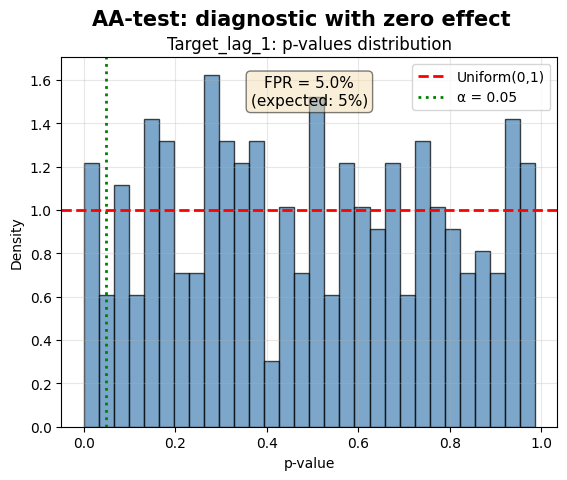

In [10]:
from IPython.display import display

from hypex.analyzers import AADryTestAnalyzer
from hypex.utils import ExperimentDataEnum

experiment_data = diagnostic._experiment_data
plot_id = experiment_data.get_one_id(AADryTestAnalyzer, ExperimentDataEnum.variables)
display(experiment_data.variables[plot_id]["AATest"])

The bars show the density of p-values across the candidate splits. The dashed red line marks the uniform density, and the vertical green line marks the 0.05 significance threshold. Look for a concentration of small p-values to the left of the threshold.

`FPR` is the proportion of splits with a p-value below the threshold. In this run, the observed 5.0% matches the expected 5%. Finite runs can differ from the expected rate. Because splits reuse the same users, interpret this as a diagnostic for the input data.

<a id="aa-float32"></a>

## Reduce floating-point precision

`float32=True` controls numeric precision independently of the A/A diagnostic. Check the metric type in a separate run with one split.

Use `data` on the selected column to inspect its pandas dtype.

In [11]:
compact_split = AATest(random_states=[42], float32=True).execute(split_data)
str(compact_split.best_split.select("Target_lag_1").data.dtypes.iloc[0])

'float32'

`Target_lag_1` has dtype `float32`.

<a id="aa-grid"></a>

## Define a custom search grid

`additional_params` supplies candidate values for an executor and replaces the default grid for that class. Give `AASplitter` two seeds and two control shares.

`additional_params` defines the grid in this example, so the top-level `random_states` and `control_size` arguments can be omitted.

In [12]:
grid = AATest(
    additional_params={
        AASplitter: {"random_state": [0, 1], "control_size": [0.4, 0.6]}
    }
).execute(aa_data)
grid.experiments.select("splitter_id")

,splitter_id
0,AASplitter┴cs 0.4|rs 0┴
1,AASplitter┴cs 0.6|rs 0┴
2,AASplitter┴cs 0.4|rs 1┴
3,AASplitter┴cs 0.6|rs 1┴


The four rows cover all combinations of the two seeds and two control shares.

<a id="aa-equal-variance"></a>

## Compare variance assumptions

Keep the seed and control share fixed. `equal_variance=False` selects Welch's test, and `True` selects a t-test with pooled variance. Compare the p-values on the same split.

`control_size` and `random_states` fix the design across runs. Change `equal_variance` to choose the t-test variant.

In [13]:
welch = AATest(
    control_size=0.6, random_states=[10], equal_variance=False
).execute(aa_data)
pooled = AATest(
    control_size=0.6, random_states=[10], equal_variance=True
).execute(aa_data)

welch_p = welch.best_split_statistics.get_values(row=0, column="TTest p-value")
pooled_p = pooled.best_split_statistics.get_values(row=0, column="TTest p-value")
{"Welch": welch_p, "equal variances": pooled_p}

{'Welch': 0.6881676650651863, 'equal variances': 0.6921920300879605}

The p-values are close and give the same decision at 0.05. Choose the variance assumption in advance based on the design and the metric.

<a id="aa-categorical"></a>

## Check categorical balance

Assign `TargetRole(str)` to `segment` to compare the frequencies of two historical categories. Use an unstratified split with `control_size=0.3`. To split within the categories, also mark the segmentation column for stratification.

The metric's role and type select the categorical test. The control share and seeds configure the search independently of the chi-square test.

In [15]:
categorical_data = Dataset(
    roles={"segment": TargetRole(str)},
    data=frame[["segment"]],
)
categorical_aa = AATest(
    control_size=0.3,
    random_states=[10, 11, 12],
).execute(categorical_data)
categorical_aa.best_split_statistics

,feature,group,control mean,test mean,difference,difference %,Chi2Test pass,Chi2Test p-value
0,segment,test_1,None,None,None,None,OK,0.928773


`segment` has a chi-square p-value for the comparison of category frequencies. If counts are small, check the sample sizes and decide in advance which rare categories to combine. For a stratified split, also check missing stratum values. HypEx excludes rows with missing stratum values when building the final split.

<a id="aa-arguments"></a>

## Find an example by argument

- `n_iterations` — [number of candidate splits](#aa-speed) and [number of A/A diagnostic runs](#aa-diagnostic).
- `control_size`, `stratification`, and `random_states` — [control share, seeds, and stratification](#aa-split).
- `sample_size` and `early_stopping` — [subsampling and the number of candidate splits](#aa-speed).
- `additional_params` — [combinations of seeds and control shares](#aa-grid).
- `equal_variance` and `t_test_equal_var` — [compare p-values and check the deprecated alias](#aa-equal-variance).
- `groups_sizes` — [proportions for a control and two test groups](#aa-groups).
- `float32` — [numeric precision](#aa-float32).
- `dry_test` — [Type I error diagnostics](#aa-diagnostic).

See how to [run the same A/A test on pandas and Spark](SparkBackend.ipynb#spark-aa).

If some users already have an assignment, see the [ConstGroupRole guide](../how_to_guide/aa-fixed-groups.ipynb).

Use the selected split to [analyze orders in an A/B test](../how_to_guide/assignment-to-ab.ipynb). Estimate the required traffic with the [sample size guide](../how_to_guide/plan-sample-size.ipynb).